In [1]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
from matplotlib import cm
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
%matplotlib inline

import torch
import torchvision

from torch import nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
#import wget

In [2]:
#!pip install wget

In [3]:
#url = 'https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip'
#wget.download(url)

In [4]:
#import os
#os.getcwd()

In [5]:
from pathlib import Path
print("Full path:", Path.cwd())
print("Folder name:", Path.cwd().name)

Full path: D:\projects\dl_2025
Folder name: dl_2025


In [6]:
from IPython.display import clear_output

def plot_losses(train_losses, test_losses, train_accuracies, test_accuracies):
    clear_output()
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    axs[0].plot(range(1, len(train_losses) + 1), train_losses, label='train')
    axs[0].plot(range(1, len(test_losses) + 1), test_losses, label='test')
    axs[0].set_ylabel('loss')

    axs[1].plot(range(1, len(train_accuracies) + 1), train_accuracies, label='train')
    axs[1].plot(range(1, len(test_accuracies) + 1), test_accuracies, label='test')
    axs[1].set_ylabel('accuracy')

    for ax in axs:
        ax.set_xlabel('epoch')
        ax.legend()

    plt.show()

def training_epoch(model, optimizer, criterion, train_loader, tqdm_desc, wandb_project=None):
    """Одна эпоха обучения"""
    train_loss, train_accuracy = 0.0, 0.0
    model.train()
    for images, labels in tqdm(train_loader, desc=tqdm_desc): # подгрузили текстовый индикатор использования
        #images = images.to(device)
        #labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.shape[0]
        train_accuracy += (logits.argmax(dim=1) == labels).sum().item()

        if wandb_project:
            metrics = {
                "batch-train/loss": loss.item()
            }
            wandb.log(metrics)

    train_loss /= len(train_loader.dataset)
    train_accuracy /= len(train_loader.dataset)
    return train_loss, train_accuracy


@torch.no_grad()
def validation_epoch(model, criterion, val_loader, tqdm_desc):
    """Прогнозы на валидации"""

    val_loss, val_accuracy = 0.0, 0.0
    model.eval()
    for images, labels in tqdm(val_loader, desc=tqdm_desc):
        #images = images.to(device)
        #labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        val_loss += loss.item() * images.shape[0]
        val_accuracy += (logits.argmax(dim=1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_accuracy /= len(val_loader.dataset)
    return val_loss, val_accuracy


def train(model, optimizer, criterion, train_loader, val_loader, num_epochs, scheduler=None, wandb_project=None):
    """Обучение модели"""
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    # подключаем wandb
    if wandb_project:
        wandb.init(project=wandb_project)
        wandb.watch(model)

    for epoch in range(1, num_epochs + 1):
        train_loss, train_accuracy = training_epoch(
            model, optimizer, criterion, train_loader,
            tqdm_desc=f'Training {epoch}/{num_epochs}',
            wandb_project=wandb_project
        )
        val_loss, val_accuracy = validation_epoch(
            model, criterion, val_loader,
            tqdm_desc=f'Validating {epoch}/{num_epochs}'
        )

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        # функция для смены lr по расписанию
        if scheduler is not None:
            scheduler.step()

        if wandb_project:
            metrics = {
                "train/loss": train_loss / len(train_loader.dataset),
                "train/accuracy": train_accuracy / len(train_loader.dataset),
                "val/loss": val_loss,
                "val/accuracy": val_accuracy
            }
            wandb.log(metrics)
        else:
          plot_losses(train_losses, val_losses, train_accuracies, val_accuracies)

    # печатаем метрики
    print(f"Epoch: {epoch}, loss: {np.mean(val_loss)}, accuracy: {np.mean(val_accuracy)}")

In [13]:
normalize = T.Normalize(mean=[0.4914, 0.4822, 0.4465],
            std=[0.247, 0.243, 0.261])

test_transform = T.Compose([
    # 256x256; можно сначала обрезать центр, а потом сделать ресайз
    T.Resize(256),
    # обрезаем центр
    T.CenterCrop(224),
    T.ToTensor(),
    normalize
])

# указываем дорогу к датасету, вытягиваем папку трейн
dataset = ImageFolder(
    "data/cats_and_dogs_filtered/train",
    transform = test_transform
)

# разбиваем папку трейн на две части (трейн и вал)
train_dataset, val_dataset = torch.utils.data.random_split(
    dataset, [int(0.8 * len(dataset)), len(dataset) - int(0.8 * len(dataset))]
)

# вытягиваем папку валидейшн
test_dataset = ImageFolder(
    "data/cats_and_dogs_filtered/validation",
    transform = test_transform
)

In [ ]:
# 48:20 / 48:22
# Альтернативная ветка ячейки выше, тут разные трансформаторы для разной папки
# (для трейна более случайно крутим-вертим картинки)
normalize = T.Normalize(mean=[0.4914, 0.4822, 0.4465],
            std=[0.247, 0.243, 0.261])

train_transform = T.Compose([
    T.RandomResizedCrop(224),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    normalize
])

test_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    normalize
])

dataset = ImageFolder(
    "data/cats_and_dogs_filtered/train",
    transform = train_transform
)

train_dataset, val_dataset = torch.utils.data.random_split(
    dataset, [int(0.8 * len(dataset)), len(dataset) - int(0.8 * len(dataset))]
)

test_dataset = ImageFolder(
    "data/cats_and_dogs_filtered/validation",
    transform = test_transform
)

In [14]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size     = 32,
    shuffle        = True,
    pin_memory     = True,   # Подгружает данные до использования, что при считывании с жесткого диска ускоряет итерирование
    num_workers    = 0
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size     = 4096,
    shuffle        = False,
    pin_memory     = True,
    num_workers    = 0
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size     = 4096,
    shuffle        = False,
    pin_memory     = True,
    num_workers    = 0
)

In [15]:
next(iter(dataset))

(tensor([[[ 1.9321,  1.9480,  1.9480,  ...,  2.0115,  2.0115,  2.0274],
          [ 1.9321,  1.9480,  1.9480,  ...,  2.0115,  2.0115,  2.0274],
          [ 1.9162,  1.9321,  1.9321,  ...,  2.0115,  2.0115,  2.0274],
          ...,
          [-0.7193, -0.7352, -0.7511,  ..., -1.6243, -1.6243, -1.6084],
          [-0.7670, -0.7670, -0.7670,  ..., -1.6402, -1.6243, -1.6243],
          [-0.7987, -0.7828, -0.7670,  ..., -1.6084, -1.6402, -1.6719]],
 
         [[ 1.3078,  1.3240,  1.3240,  ...,  1.6629,  1.6629,  1.6790],
          [ 1.3078,  1.3240,  1.3240,  ...,  1.6629,  1.6629,  1.6790],
          [ 1.2917,  1.3078,  1.3078,  ...,  1.6629,  1.6629,  1.6790],
          ...,
          [-1.0968, -1.1129, -1.1290,  ..., -1.6939, -1.6939, -1.6293],
          [-1.1452, -1.1452, -1.1452,  ..., -1.7100, -1.6939, -1.6455],
          [-1.1775, -1.1613, -1.1452,  ..., -1.6939, -1.7100, -1.6939]],
 
         [[ 0.1674,  0.1824,  0.1824,  ...,  0.5581,  0.5581,  0.5731],
          [ 0.1674,  0.1824,

In [16]:
dataset[0][0].shape

torch.Size([3, 224, 224])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9577202..2.0591094].


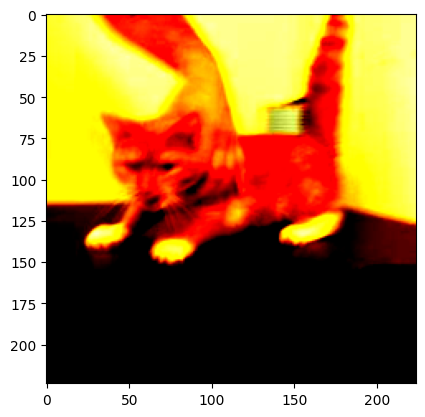

In [17]:
image, label = next(iter(dataset))
plt.imshow(np.transpose(image, (1, 2, 0)))
plt.show()

In [ ]:
class FcNet(nn.Module):

    # инициализируем слои
    def __init__(self, input_shape, hide_neurons=32, num_classes=10):
        # инициализируем функцию-конструктор из модуля
        super().__init__()
        # объявляем модель и что мы можем в ней подобовлять
        self.model = nn.Sequential(

            nn.Flatten(), # превращаем картинку 28 на 28 в вектор 784
            nn.Linear(input_shape, hide_neurons), # линейный слой, преобразует вектор 784 в вектор 32
            nn.ReLU(), # нелинейность
            nn.Linear(hide_neurons, hide_neurons // 2), # линейный слой, преобразует вектор 784 в вектор 16
            nn.ReLU(), # нелинейность
            nn.Linear(hide_neurons // 2, num_classes) # линейный слой, преобразует вектор 784 в вектор 10
            
        )

    # прогоняем по слоям
    def forward(self, x):
        # распаковываем элемент в матрицу, начиная со второго элемента (первый -- не координата)
        return self.model(x)

In [ ]:
IMG_SIZE = 28
NUM_EPOCH = 5

model_fc = FcNet(IMG_SIZE**2)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_fc.parameters(), lr=0.01, momentum=0)

In [ ]:
train(

    model_fc, optimizer, criterion,
    train_loader, val_loader,
    NUM_EPOCH
    
)

In [ ]:
class ConvNet(nn.Module):

    def __init__(self, image_channels=1):
        super().__init__()
        # энкодер все перегоняет в вектор
        self.encoder = nn.Sequential(  # 28 x 28
            
            nn.Conv2d(in_channels=image_channels, out_channels=4,
                      kernel_size=3, padding='same'),  # 28 x 28, padding такой же, чтобы не падала размерность изображения,
                                                       # out_channels -- сколько сверток надо делать
            nn.ReLU(),
            nn.MaxPool2d(2),  # 14 x 14

            nn.Conv2d(in_channels=4, out_channels=8,
                      kernel_size=3, padding='same'),  # 14 x 14
            nn.ReLU(),
            nn.MaxPool2d(2),  # 7 x 7

            nn.Conv2d(in_channels=8, out_channels=16,
                      kernel_size=3, padding='same'),  # 7 x 7
            nn.ReLU(),
            nn.MaxPool2d(2)  # 3 x 3
        )

        # классификатор на сформированном векторе: он выводит итоговые классы
        self.head = nn.Sequential(
            nn.Linear(in_features=144, out_features=32),
            nn.ReLU(),
            nn.Linear(in_features=32, out_features=10)
        )
    # форвард добывает прогнозы
    def forward(self, x):
        # x: B x 1 x 28 x 28
        out = self.encoder(x)   # out: B x 392
        out = nn.Flatten()(out) # out: B x 128
        out = self.head(out)    # out: B x 10
        return out

    # функция эмбеддинга: вытягивает из сверточной части выше (self.encoder) векторыЮ в которых как раз проявились отличительные свойста
    # объектов; тут они сохраняются, чтобы потом их рассматривать, изучать и прочее; тут мы просто такие ветора добываем
    def get_embedding(self, x):
        out = self.encoder(x)
        return nn.Flatten()(out)

In [ ]:
model_cnn = ConvNet()
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0)

In [ ]:
train(model_cnn, optimizer, criterion, train_loader, val_loader, NUM_EPOCH)

In [ ]:
model_cnn_adam = ConvNet()
optimizer = torch.optim.Adam(model_cnn_adam.parameters(), lr=1e-3)

In [ ]:
train(model_cnn_adam, optimizer, criterion, train_loader, val_loader, NUM_EPOCH)